# US Early Childhood Care Arrangements, 2016 and 2019, Starter Notebook

![cover](https://raw.githubusercontent.com/montessoritheory/us-early-childhood-care/main/images/cover.png)

This notebook loads the harmonized NCES Early Childhood Program Participation files and shows how to compute **weighted estimates with correct standard errors**. Each row is one child from birth to age 5 who is not yet in kindergarten. It answers these questions.

1. How many young children are in weekly nonparental care, and of which kind?
2. How does center-based care change with age and with family income?
3. What do parents look for, and what do they pay?

Dataset by [Montessori Theory](https://www.montessori-theory.com/), CC BY 4.0. Source, NCES NHES.

In [1]:
import os, glob, numpy as np, pandas as pd, matplotlib.pyplot as plt

# works on Kaggle, locally and straight from GitHub
hits = glob.glob('/kaggle/input/**/early_childhood_care_2016_2019.csv', recursive=True)
GITHUB = 'https://raw.githubusercontent.com/montessoritheory/us-early-childhood-care/main/data'
BASE = os.path.dirname(hits[0]) if hits else next((p for p in ['data', '../data'] if os.path.exists(f'{p}/early_childhood_care_2016_2019.csv')), GITHUB)

kids = pd.read_csv(f'{BASE}/early_childhood_care_2016_2019.csv', dtype={'child_id': str})
rep_path = next((p for p in glob.glob('/kaggle/input/**/replicate_weights_2016_2019.*', recursive=True)), f'{BASE}/replicate_weights_2016_2019.zip')
rep = pd.read_csv(rep_path, dtype={'child_id': str})
kids = kids.merge(rep, on=['survey_year', 'child_id'])
print(kids.shape, kids.survey_year.value_counts().to_dict())

/tmp/ipykernel_980/2390055948.py:8: DtypeWarning: Columns (0: center_type_2016, 1: center_run_by_religious_group_2016) have mixed types. Specify dtype option on import or set low_memory=False.
  kids = pd.read_csv(f'{BASE}/early_childhood_care_2016_2019.csv', dtype={'child_id': str})


(12936, 156) {2019: 7092, 2016: 5844}


In [2]:
R = 80
def pct(df, num):
    """Weighted percent with a jackknife (JK1) standard error."""
    p = 100 * df.final_weight[num].sum() / df.final_weight.sum()
    reps = np.array([100 * df[f'FEWT{i}'][num].sum() / df[f'FEWT{i}'].sum() for i in range(1, R + 1)])
    return round(p, 1), round(np.sqrt((R - 1) / R * ((reps - p) ** 2).sum()), 2)

plt.rcParams.update({'figure.facecolor': '#F7F3EC', 'axes.facecolor': '#F7F3EC', 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#E4DED3', 'font.size': 12})
TC, BLUE, OLIVE, GOLD = '#B4532F', '#1F72B8', '#7F9A1F', '#D19A2A'

## 1. Weekly care, all children

The NCES headline measure is having at least one nonparental arrangement scheduled at least once a week. For 2019 these estimates match the published NCES table (59 %, and among them 38 % relative, 20 % nonrelative, 62 % center-based).

In [3]:
rows = []
for y, g in kids.groupby('survey_year'):
    for col in ['weekly_care', 'weekly_relative_care', 'weekly_nonrelative_care', 'weekly_center_program']:
        rows.append([y, col, *pct(g, g[col] == 'Yes')])
pd.DataFrame(rows, columns=['year', 'indicator', 'percent', 'se'])

,year,indicator,percent,se
0,2016,weekly_care,59.5,0.96
1,2016,weekly_relative_care,24.2,0.74
2,2016,weekly_nonrelative_care,13.0,0.43
3,2016,weekly_center_program,35.2,0.79
4,2019,weekly_care,59.4,0.85
5,2019,weekly_relative_care,22.5,0.73
6,2019,weekly_nonrelative_care,11.7,0.44
7,2019,weekly_center_program,37.1,0.68


## 2. Center-based care by age and by income

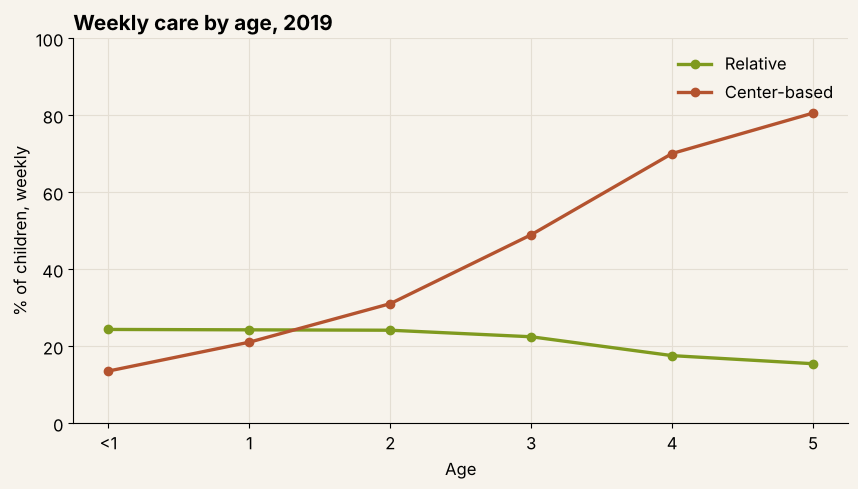

In [4]:
y19 = kids[kids.survey_year == 2019]
fig, ax = plt.subplots(figsize=(10, 5))
for col, c, lab in [('weekly_relative_care', OLIVE, 'Relative'), ('weekly_center_program', TC, 'Center-based')]:
    v = [pct(y19[y19.child_age == a], y19[y19.child_age == a][col] == 'Yes')[0] for a in range(6)]
    ax.plot(range(6), v, marker='o', lw=2.4, color=c, label=lab)
ax.set_xticks(range(6)); ax.set_xticklabels(['<1', '1', '2', '3', '4', '5']); ax.set_ylim(0, 100)
ax.set_xlabel('Age'); ax.set_ylabel('% of children, weekly'); ax.legend(frameon=False)
ax.set_title('Weekly care by age, 2019', loc='left', fontsize=15, fontweight='bold'); plt.show()

In [5]:
order = ['$0 to $10,000', '$10,001 to $20,000', '$20,001 to $30,000', '$30,001 to $40,000', '$40,001 to $50,000', '$50,001 to $60,000', '$60,001 to $75,000', '$75,001 to $100,000', '$100,001 to $150,000', '$150,001 or more']
older = y19[y19.child_age >= 3]
pd.DataFrame([[inc, *pct(older[older.household_income == inc], older[older.household_income == inc].weekly_center_program == 'Yes')] for inc in order], columns=['household_income', 'percent_center_age_3_to_5', 'se'])

,household_income,percent_center_age_3_to_5,se
0,"$0 to $10,000",42.3,5.34
1,"$10,001 to $20,000",61.8,4.88
2,"$20,001 to $30,000",53.9,4.79
3,"$30,001 to $40,000",47.3,4.67
4,"$40,001 to $50,000",45.0,4.86
5,"$50,001 to $60,000",47.8,4.36
6,"$60,001 to $75,000",56.0,3.67
7,"$75,001 to $100,000",59.7,2.96
8,"$100,001 to $150,000",74.7,2.43
9,"$150,001 or more",83.4,1.73


## 3. What parents look for, and what they pay

The weekly cost is out of pocket, per child, for families who pay, in current dollars.

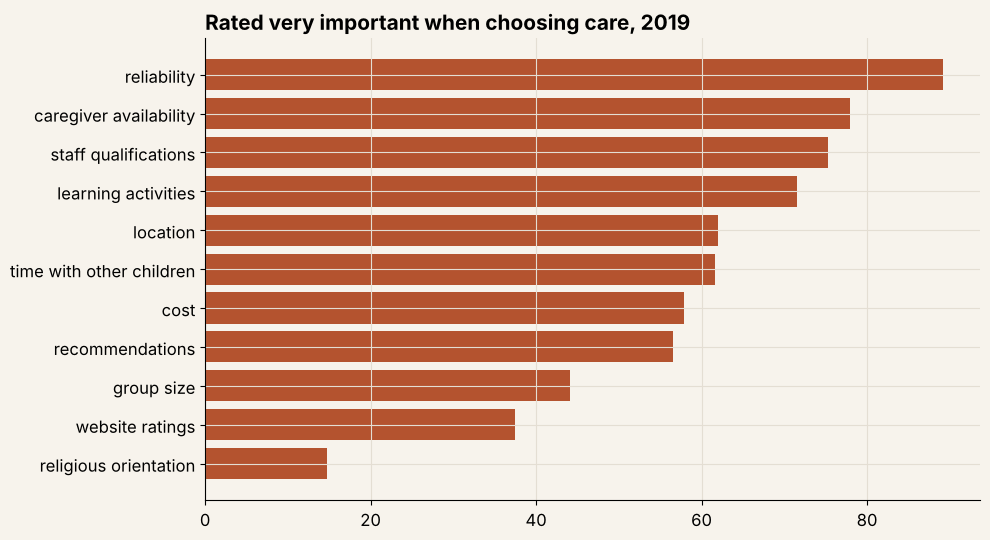

Mean weekly center cost per child, 2019: $ 151.26


In [6]:
factors = [c for c in kids.columns if c.startswith('importance_')]
imp = []
for col in factors:
    g = y19[y19[col].notna() & (y19[col] != 'Not available')]
    imp.append([col.replace('importance_', '').replace('_', ' '), *pct(g, g[col] == 'Very important')])
imp = pd.DataFrame(imp, columns=['factor', 'percent_very_important', 'se']).sort_values('percent_very_important')
fig, ax = plt.subplots(figsize=(10, 6)); ax.barh(imp.factor, imp.percent_very_important, color=TC)
ax.set_title('Rated very important when choosing care, 2019', loc='left', fontsize=15, fontweight='bold'); plt.show()

pay = y19[y19.center_cost_weekly_per_child > 0]
print('Mean weekly center cost per child, 2019: $', round(np.average(pay.center_cost_weekly_per_child, weights=pay.final_weight), 2))

## 4. Ideas to go further

- Compare home learning activities (`times_read_to_past_week`, `taught_letters_words_numbers_past_week`) with early skills (`recognizes_letters`, `counts_up_to`).
- Model the probability of center-based care with age, income, parent work status and locale, using the weights.
- Look at `difficulty_finding_care` and `main_difficulty` by region and locale to see where care is hardest to find.

For what Montessori looks like from 3 to 6, see [Montessori for preschoolers](https://www.montessori-theory.com/montessori-preschoolers/) on Montessori Theory.